# BPCS-Steganography

Implementation of the algorithm from the paper *Principle and applications of BPCS-Steganography* (Kawaguchi, Eason, 1998).

## 1. Overview

**Idea.** A human cannot perceive any shape in a very complicated, "noise-like" binary pattern. We therefore decompose the carrier image (the *vessel*) into bit-planes and **replace every noise-like region with secret data** — the image looks the same, yet the embedding capacity reaches about 50% of its size (traditional methods: 5–15%).

**Embedding algorithm:**
1. Convert the RGB image from Pure Binary Code (PBC) to Canonical Gray Code (CGC) and split it into 24 bit-planes (3 channels × 8 bits).
2. Divide each bit-plane into 8×8 blocks and compute the complexity of each block, $\alpha = k / k_{max}$, where $k$ is the length of the black-and-white border and $k_{max}=112$.
3. Blocks with $\alpha \ge \alpha_0$ (typically $\alpha_0 = 0.3$) are noise-like — this is where the data is hidden.
4. Split the secret file into 8-byte chunks (= 64 bits = one 8×8 block). A block that is too simple ($\alpha < \alpha_0$) is **conjugated**: $P^* = P \oplus W_c$ ($W_c$ is a checkerboard), which gives $\alpha(P^*) = 1 - \alpha(P)$. The fact is recorded in the *conjugation map*.
5. Replace the noise-like blocks with the secret blocks (and the conjugation map), then convert CGC back to PBC.

Extraction is the reverse of these steps. In addition, following the *Customization* section of the paper, the header and the map are "whitened" with a pseudo-random stream, and the order of the blocks depends on a key.

## 2. Data preparation

We use four RGB images (`uint8`): an artificial checkerboard and three photographs from `scikit-image`. The checkerboard is deliberately a **bad vessel** — it consists of large flat areas, so it contains no noise-like blocks (see the paper's remark about flat regions). Image sizes that are not divisible by 8 (e.g. `cat`) are handled by using only the full blocks.

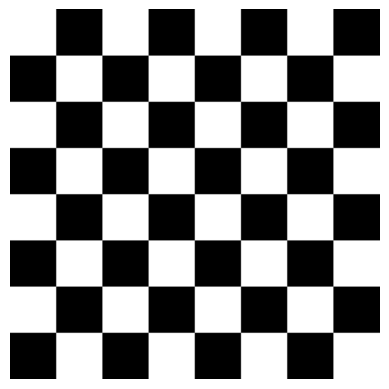

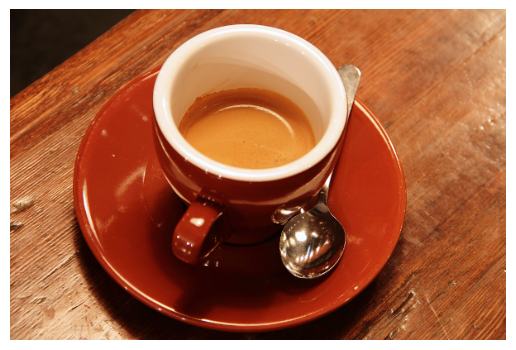

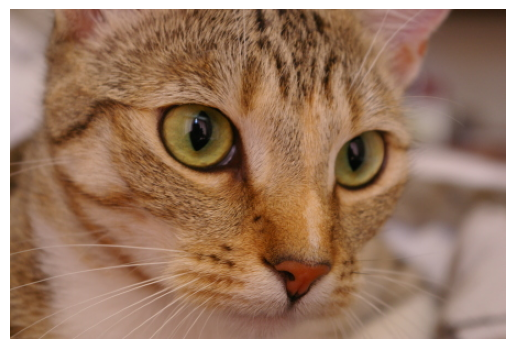

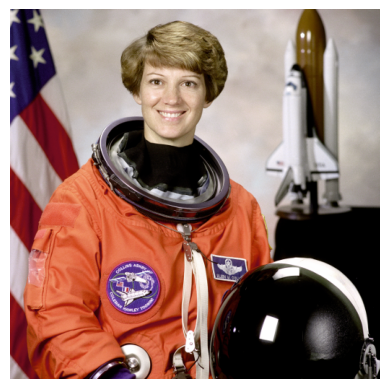

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img in imgs_color:
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## 3. Implementation

### 3.1 Gray code and bit-planes

In pure binary code a tiny change in brightness can flip many bits at once (e.g. `01111111` → `10000000`, the so-called *Hamming cliffs*), which makes flat regions look complex. In Gray code, `g = b ^ (b >> 1)`, neighbouring values differ by a single bit, so the complexity of the bit-planes reflects the real variation of the image much better.

In [2]:
BLOCK = 8
MAX_BORDER = 2 * BLOCK * (BLOCK - 1)   # 112 = max. number of B-W changes in an 8x8 block


def pbc_to_cgc(img):
    """Pure Binary Code -> Canonical Gray Code (element-wise)."""
    return img ^ (img >> 1)


def cgc_to_pbc(g):
    """Canonical Gray Code -> Pure Binary Code."""
    b = g.copy()
    for shift in (1, 2, 4):
        b ^= b >> shift
    return b


def to_planes(img):
    """RGB image (H, W, 3) -> CGC bit-planes (24, H8, W8); H8, W8 are the sizes cropped to multiples of 8."""
    h, w = img.shape[0] // BLOCK * BLOCK, img.shape[1] // BLOCK * BLOCK
    g = pbc_to_cgc(img[:h, :w])
    bits = (g[..., None] >> np.arange(8)) & 1                       # (h, w, 3, 8)
    return bits.transpose(2, 3, 0, 1).reshape(24, h, w).astype(np.uint8)


def from_planes(planes, img):
    """Inverse of to_planes; the part of the image outside the full blocks is copied from the original."""
    _, h, w = planes.shape
    weights = (1 << np.arange(8)).astype(np.uint8)[None, :, None, None]
    g = (planes.reshape(3, 8, h, w) * weights).sum(axis=1, dtype=np.uint8)   # (3, h, w)
    out = img.copy()
    out[:h, :w] = cgc_to_pbc(g.transpose(1, 2, 0))
    return out


x = np.arange(256, dtype=np.uint8)
assert (cgc_to_pbc(pbc_to_cgc(x)) == x).all()
assert (from_planes(to_planes(imgs_color[1]), imgs_color[1]) == imgs_color[1]).all()

### 3.2 Block complexity and conjugation

The complexity of a block is the number of black/white colour changes along its rows and columns divided by the maximum possible number (112):

$$\alpha = \frac{k}{k_{max}}, \qquad 0 \le \alpha \le 1.$$

Conjugation $P^* = P \oplus W_c$ flips every colour change between neighbouring pixels, so $\alpha(P^*) = 1-\alpha(P)$ and $(P^*)^* = P$. Thanks to this, any secret block that is too simple can be turned into a noise-like one and restored later.

In [3]:
WC = (np.indices((BLOCK, BLOCK)).sum(axis=0) % 2).astype(np.uint8)   # checkerboard Wc (0 in the top-left corner)


def to_blocks(planes):
    """(P, H, W) -> view of shape (P, H/8, W/8, 8, 8)."""
    P, h, w = planes.shape
    return planes.reshape(P, h // BLOCK, BLOCK, w // BLOCK, BLOCK).transpose(0, 1, 3, 2, 4)


def from_blocks(blocks):
    P, hb, wb = blocks.shape[:3]
    return blocks.transpose(0, 1, 3, 2, 4).reshape(P, hb * BLOCK, wb * BLOCK)


def complexity(b):
    """Complexity alpha of blocks; works on arrays of shape (..., 8, 8)."""
    k = (b[..., 1:] != b[..., :-1]).sum(axis=(-1, -2)) + (b[..., 1:, :] != b[..., :-1, :]).sum(axis=(-1, -2))
    return k / MAX_BORDER


def conjugate(b):
    return b ^ WC


p = np.random.default_rng(0).integers(0, 2, (BLOCK, BLOCK), dtype=np.uint8)
assert np.isclose(complexity(conjugate(p)), 1 - complexity(p))
assert (conjugate(conjugate(p)) == p).all()

### 3.3 Embedding

The stream of blocks written into the image has the form: **[header] [data blocks] [conjugation map]**.

- header – the length of the secret data (8 bytes = one block),
- data blocks – 8 bytes each, conjugated if $\alpha < \alpha_0$,
- conjugation map – 1 bit per data block (64 bits = 1 block); it is "whitened" with a key-dependent pseudo-random stream so that it is noise-like itself.

The blocks are written into the noise-like positions of the image: from the least significant bit-planes towards the most significant ones, and within a single bit level in an order determined by the key. (This is our extension — the paper does not specify the order — so that a partially filled vessel gets its changes in the least visible bits.) Because the inserted blocks always have $\alpha \ge \alpha_0$, the set of noise-like positions after embedding is the same as before, so the decoder finds exactly the same positions.

In [4]:
import struct


def bytes_to_blocks(data):
    """Bytes -> 8x8 bit blocks (8 bytes per block, zero-padded)."""
    data = data + bytes(-len(data) % 8)
    return np.unpackbits(np.frombuffer(data, np.uint8)).reshape(-1, BLOCK, BLOCK)


def blocks_to_bytes(blocks):
    return np.packbits(blocks.reshape(-1)).tobytes()


def whiten(blocks, key, salt):
    """XOR with a key-dependent pseudo-random stream (XOR is its own inverse)."""
    mask = np.random.default_rng([key, salt]).integers(0, 2, blocks.shape, dtype=np.uint8)
    return blocks ^ mask


def noise_positions(blocks, key, alpha0):
    """Positions (plane, i, j) of noise-like blocks: least significant bits first, random (keyed) order within a bit level."""
    pos = np.argwhere(complexity(blocks) >= alpha0)
    pos = pos[np.random.default_rng([key, 2]).permutation(len(pos))]
    return pos[np.argsort(pos[:, 0] % 8, kind="stable")]               # plane p = 8 * channel + bit


def capacity(img, alpha0=0.3):
    """Maximum size of the secret data in bytes (the header and the map take up some of the blocks)."""
    free = len(noise_positions(to_blocks(to_planes(img)), 0, alpha0)) - 1     # minus the header block
    n = max(free, 0) * 64 // 65
    while n > 0 and n + -(-n // 64) > free:   # n data blocks + ceil(n/64) map blocks
        n -= 1
    return n * BLOCK


def embed(img, secret, key=0, alpha0=0.3):
    planes = to_planes(img)
    blocks = to_blocks(planes)
    pos = noise_positions(blocks, key, alpha0)

    payload = bytes_to_blocks(secret)
    n = len(payload)
    simple = complexity(payload) < alpha0# which blocks must be conjugated
    payload = np.where(simple[:, None, None], conjugate(payload), payload)
    cmap = np.pad(simple.astype(np.uint8), (0, -n % 64)).reshape(-1, BLOCK, BLOCK)

    header = whiten(bytes_to_blocks(struct.pack("<Q", len(secret))), key, 0)
    cmap = whiten(cmap, key, 1)
    if (complexity(np.concatenate([header, cmap])) < alpha0).any():
        raise ValueError("The header or the map is too simple - change the key.")

    stream = np.concatenate([header, payload, cmap])
    if len(stream) > len(pos):
        raise ValueError(f"Too much data: {len(stream)} blocks needed, {len(pos)} available.")

    blocks[tuple(pos[:len(stream)].T)] = stream
    return from_planes(from_blocks(blocks), img)

### 3.4 Extraction

The decoder performs the same steps in reverse: it finds the noise-like blocks of the stego image (in CGC), reads the header, then the data blocks and the conjugation map, and finally conjugates back the blocks that were conjugated. Without the correct key (and threshold $\alpha_0$) the positions, the header and the map are unreadable.

In [5]:
def extract(stego, key=0, alpha0=0.3):
    blocks = to_blocks(to_planes(stego))
    pos = noise_positions(blocks, key, alpha0)
    if len(pos) == 0:
        raise ValueError("The image contains no noise-like blocks.")

    def get(a, b):    # blocks number a..b-1 in embedding order
        return blocks[tuple(pos[a:b].T)]

    length = struct.unpack("<Q", blocks_to_bytes(whiten(get(0, 1), key, 0)))[0]
    if length > len(pos) * BLOCK:
        raise ValueError("No data, or wrong key / threshold.")

    n = -(-length // 8)
    cmap = whiten(get(1 + n, 1 + n + -(-n // 64)), key, 1).reshape(-1)[:n].astype(bool)
    payload = np.where(cmap[:, None, None], conjugate(get(1, 1 + n)), get(1, 1 + n))
    return blocks_to_bytes(payload)[:length]

## 4. Usage

For each image we embed an amount of data equal to half of its capacity, extract it and compare it with the original. Filling 100% of the capacity also works and the data is still recovered without errors, but then the changes reach the higher bit-planes and become visible in textured areas (wood, fur) - set `FILL` to `1.0` to see it. The secret data are random bytes (resembling compressed or encrypted data - randomization is an advantage of the method) with a block of zeros added to force the conjugation of simple blocks. Image quality is measured with PSNR.

checkerboard capacity: 0 B - the image has no noise-like blocks
coffee       capacity:  312,336 B (43.4% of image), embedded  156,168 B | conjugated blocks:  1952 | PSNR: 45.0 dB | extracted correctly: True
cat          capacity:  162,680 B (40.1% of image), embedded   81,336 B | conjugated blocks:  1017 | PSNR: 45.5 dB | extracted correctly: True
astronaut    capacity:  297,760 B (37.9% of image), embedded  148,880 B | conjugated blocks:  1861 | PSNR: 45.7 dB | extracted correctly: True


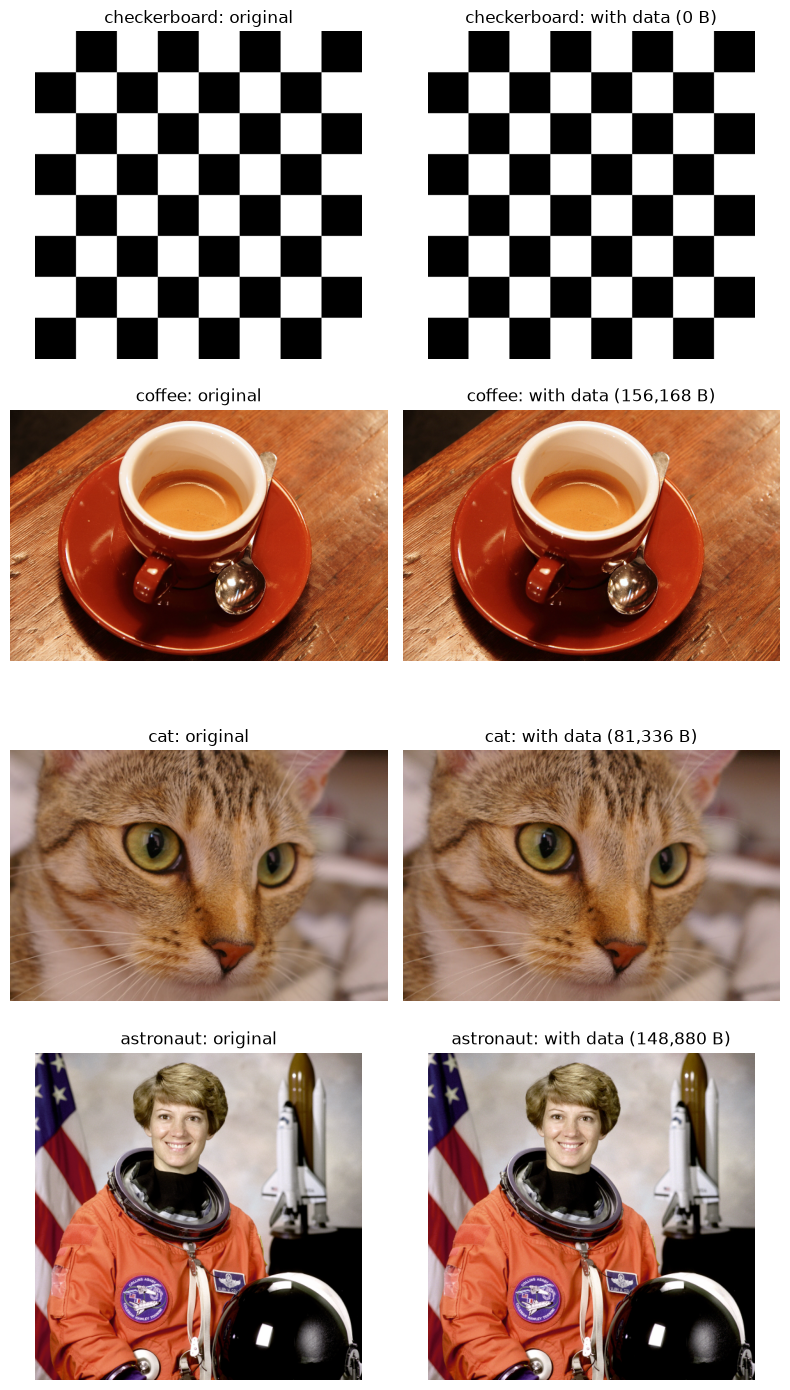

Wrong key: No data, or wrong key / threshold.


In [6]:
def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return np.inf if mse == 0 else 10 * np.log10(255 ** 2 / mse)


KEY, ALPHA0, FILL = 1234, 0.3, 0.5
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(imgs_color), 2, figsize=(8, 3.5 * len(imgs_color)))

for img, name, (ax_orig, ax_stego) in zip(imgs_color, image_names, axes):
    cap = capacity(img, ALPHA0)
    size = int(cap * FILL) // 8 * 8
    secret = bytearray(rng.bytes(size))
    secret[: size // 10] = bytes(size // 10)  # 10% zeros -> simple blocks to conjugate
    secret = bytes(secret)

    if cap:
        stego = embed(img, secret, KEY, ALPHA0)
        ok = extract(stego, KEY, ALPHA0) == secret
        n_conj = int((complexity(bytes_to_blocks(secret)) < ALPHA0).sum())
        print(f"{name:12s} capacity: {cap:>8,d} B ({cap / img.size:5.1%} of image), embedded {size:>8,d} B | "
              f"conjugated blocks: {n_conj:>5d} | PSNR: {psnr(img, stego):4.1f} dB | extracted correctly: {ok}")
    else:
        stego = img
        print(f"{name:12s} capacity: 0 B - the image has no noise-like blocks")

    ax_orig.imshow(img); ax_orig.set_title(f"{name}: original")
    ax_stego.imshow(stego); ax_stego.set_title(f"{name}: with data ({len(secret):,} B)")
    ax_orig.axis("off"); ax_stego.axis("off")

plt.tight_layout()
plt.show()

try: # a wrong key does not reveal the data
    extract(stego, KEY + 1, ALPHA0)
except ValueError as e:
    print("Wrong key:", e)